In [1]:
import pandas as pd

def Q1_Factors(ser, n):
    """
    ser : Série pandas de rendements
    n   : nombre de retards à inclure

    Retourne un DataFrame contenant :
    - les rendements originaux
    - les n retards
    - les n retards au carré
    """

    df = pd.DataFrame({"R_t": ser.copy()})

    # Retards
    for i in range(1, n + 1):
        df[f"R_t-{i}"] = ser.shift(i)

    # Retards au carré
    for i in range(1, n + 1):
        df[f"R_t-{i}²"] = ser.shift(i) ** 2

    df = df.dropna()

    return df

In [6]:
import pandas as pd

final = pd.read_csv("Base_Donnees_Finale.csv")

def Q1_Factors(ser, n):

    df = pd.DataFrame({"APA": ser.copy()})

    # Retards
    for i in range(1, n + 1):
        df[f"APA_Lag{i}"] = ser.shift(i)

    # Retards au carré
    for i in range(1, n + 1):
        df[f"APA_Lag{i}_Sq"] = ser.shift(i)**2

    df = df.dropna()

    return df


df_factors = Q1_Factors(final["APA"], 3)

print(df_factors.head())

        APA  APA_Lag1  APA_Lag2  APA_Lag3   APA_Lag1_Sq   APA_Lag2_Sq  \
3 -0.000556 -0.007398 -0.007018 -0.003170  5.473040e-05  4.925232e-05   
4 -0.009127 -0.000556 -0.007398 -0.007018  3.091360e-07  5.473040e-05   
5 -0.000449 -0.009127 -0.000556 -0.007398  8.330213e-05  3.091360e-07   
6 -0.012362 -0.000449 -0.009127 -0.000556  2.016010e-07  8.330213e-05   
7 -0.016614 -0.012362 -0.000449 -0.009127  1.528190e-04  2.016010e-07   

    APA_Lag3_Sq  
3  1.004890e-05  
4  4.925232e-05  
5  5.473040e-05  
6  3.091360e-07  
7  8.330213e-05  


In [7]:
import pandas as pd
import statsmodels.api as sm

def Q1_Factors(df, n):
    """
    Produit les retards et les carrés des retards.
    """
    X = pd.DataFrame(index=df.index)

    for i in range(1, n + 1):
        X[f"Lag{i}"] = df.iloc[:, 0].shift(i)
        X[f"Lag{i}_sq"] = X[f"Lag{i}"]**2

    return X


def Q1_OLS(df, n):
    """
    Régression MCO des rendements sur une constante,
    les n retards et les n retards au carré.

    Paramètres
    ----------
    df : DataFrame à une colonne
    n : entier positif

    Retour
    -------
    objet RegressionResults
    """

    y = df.iloc[:, 0]

    X = Q1_Factors(df, n)

    data = pd.concat([y, X], axis=1).dropna()

    y = data.iloc[:, 0]
    X = data.iloc[:, 1:]

    X = sm.add_constant(X)

    model = sm.OLS(y, X)
    results = model.fit()

    return results

In [9]:
import pandas as pd
import statsmodels.api as sm

final = pd.read_csv("Base_Donnees_Finale.csv")

def Q1_Factors(df, n):

    X = pd.DataFrame(index=df.index)

    for i in range(1, n + 1):
        X[f"APA_Lag{i}"] = df.iloc[:, 0].shift(i)
        X[f"APA_Lag{i}_Sq"] = X[f"APA_Lag{i}"]**2

    return X

def Q1_OLS(df, n):

    y = df.iloc[:, 0]

    X = Q1_Factors(df, n)

    data = pd.concat([y, X], axis=1).dropna()

    y = data.iloc[:, 0]
    X = data.iloc[:, 1:]

    X = sm.add_constant(X)

    return sm.OLS(y, X).fit()

resultats = Q1_OLS(final[["APA"]], 3)

print(resultats.summary())

                            OLS Regression Results                            
Dep. Variable:                    APA   R-squared:                       0.021
Model:                            OLS   Adj. R-squared:                  0.018
Method:                 Least Squares   F-statistic:                     8.032
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.34e-08
Time:                        17:44:24   Log-Likelihood:                 4271.2
No. Observations:                2265   AIC:                            -8528.
Df Residuals:                    2258   BIC:                            -8488.
Df Model:                           6                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           0.0010      0.001      1.280      

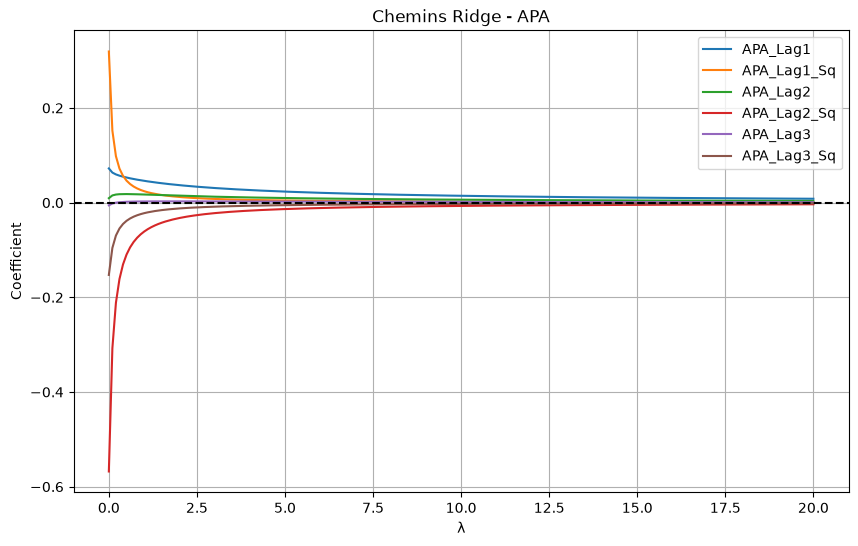

[ 0.07227776  0.31928549  0.00938622 -0.56792884 -0.00570503 -0.15270384]
             APA_Lag1  APA_Lag1_Sq  APA_Lag2  APA_Lag2_Sq  APA_Lag3  \
APA_Lag1     1.000000    -0.172435  0.061304     0.030974  0.027261   
APA_Lag1_Sq -0.172435     1.000000 -0.080823     0.146992 -0.068199   
APA_Lag2     0.061304    -0.080823  1.000000    -0.172444  0.061310   
APA_Lag2_Sq  0.030974     0.146992 -0.172444     1.000000 -0.080813   
APA_Lag3     0.027261    -0.068199  0.061310    -0.080813  1.000000   
APA_Lag3_Sq -0.110127     0.144248  0.030968     0.146980 -0.172435   

             APA_Lag3_Sq  
APA_Lag1       -0.110127  
APA_Lag1_Sq     0.144248  
APA_Lag2        0.030968  
APA_Lag2_Sq     0.146980  
APA_Lag3       -0.172435  
APA_Lag3_Sq     1.000000  


,APA_Lag1_Sq,APA_Lag2_Sq,APA_Lag3_Sq
APA_Lag1_Sq,1.000000,0.146992,0.144248
APA_Lag2_Sq,0.146992,1.000000,0.146980
APA_Lag3_Sq,0.144248,0.146980,1.000000


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

final = pd.read_csv("Base_Donnees_Finale.csv")

def Q1_Factors(df, n):

    X = pd.DataFrame(index=df.index)

    for i in range(1, n + 1):
        X[f"APA_Lag{i}"] = df.iloc[:, 0].shift(i)
        X[f"APA_Lag{i}_Sq"] = X[f"APA_Lag{i}"]**2

    return X

apa = final[["APA"]]

X = Q1_Factors(apa, 3)

df_retarde = pd.concat([apa, X], axis=1).dropna()


def Q1_Ridge(df, s, n):

    y = df.iloc[:,0]
    X = df.iloc[:,1:]

    lambdas = np.linspace(0, s, n)

    coefs = []

    for lam in lambdas:

        ridge = Ridge(alpha=lam)
        ridge.fit(X, y)

        coefs.append(ridge.coef_)

    coefs = np.array(coefs)

    plt.figure(figsize=(10,6))

    for i in range(X.shape[1]):
        plt.plot(lambdas,
                 coefs[:,i],
                 label=X.columns[i])

    plt.axhline(0,color='black',linestyle='--')

    plt.xlabel('λ')
    plt.ylabel('Coefficient')
    plt.title('Chemins Ridge - APA')

    plt.legend()
    plt.grid()

    plt.show()

    return coefs
coefs = Q1_Ridge(df_retarde, 20, 200)

print(coefs[0])


factors = Q1_Factors(final[["APA"]], 3)

corr = factors.corr()

print(corr)

corr.loc[
    ["APA_Lag1","APA_Lag2","APA_Lag3"],
    ["APA_Lag1","APA_Lag2","APA_Lag3"]
]

corr.loc[
["APA_Lag1_Sq","APA_Lag2_Sq","APA_Lag3_Sq"],
["APA_Lag1_Sq","APA_Lag2_Sq","APA_Lag3_Sq"]
]

In [2]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.model_selection import LeaveOneOut
from sklearn.model_selection import KFold
from sklearn.model_selection import cross_val_score

final = pd.read_csv("Base_Donnees_Finale.csv")

def Q1_Factors(df, n):

    X = pd.DataFrame(index=df.index)

    for i in range(1, n + 1):
        X[f"APA_Lag{i}"] = df.iloc[:, 0].shift(i)
        X[f"APA_Lag{i}_Sq"] = X[f"APA_Lag{i}"]**2

    return X

apa = final[["APA"]]

X = Q1_Factors(apa, 3)

df_retarde = pd.concat([apa, X], axis=1).dropna()

print(df_retarde.shape)

def Q1_RidgeVC(df, s, n, LOOCV):

    y = df.iloc[:, 0]
    X = df.iloc[:, 1:]

    lambdas = np.linspace(1e-8, s, n)

    best_lambda = None
    best_score = np.inf

    for lam in lambdas:

        model = Ridge(alpha=lam)

        if LOOCV:

            cv = LeaveOneOut()

        else:

            cv = KFold(
                n_splits=10,
                shuffle=True,
                random_state=123
            )

        scores = cross_val_score(
            model,
            X,
            y,
            cv=cv,
            scoring='neg_mean_squared_error'
        )

        mse = -scores.mean()

        if mse < best_score:

            best_score = mse
            best_lambda = lam

    ridge_best = Ridge(alpha=best_lambda)

    ridge_best.fit(X, y)

    beta_hat = ridge_best.coef_

    return best_lambda, beta_hat

lambda_loocv, beta_loocv = Q1_RidgeVC(
    df_retarde,
    s=100,
    n=100,
    LOOCV=True
)

print("Lambda optimal (LOOCV)")
print(lambda_loocv)

print("\nCoefficients")
print(beta_loocv)

lambda_kfold, beta_kfold = Q1_RidgeVC(
    df_retarde,
    s=20,
    n=25,
    LOOCV=False
)

print("Lambda optimal (10-fold)")
print(lambda_kfold)

print("\nCoefficients")
print(beta_kfold)


(2265, 7)


Lambda optimal (LOOCV)
100.0

Coefficients
[ 0.00185095  0.00019985  0.00081992 -0.00070146  0.00021311 -0.00028918]
Lambda optimal (10-fold)
20.0

Coefficients
[ 0.0082338   0.00104122  0.00358852 -0.0034782   0.00089428 -0.00141326]
